# Week07 군집화 과제

실행 안내: 커널을 다시 시작한 뒤 위에서부터 모든 셀을 실행하세요. 첫 코드 셀의 Windows 실행 설정은 라이브러리를 불러오기 전에 적용됩니다.

In [1]:
# Windows에서 K-means의 MKL/OpenMP 경고를 피하도록 numpy를 불러오기 전에 설정
import os
os.environ['OMP_NUM_THREADS'] = '1'
# 물리 코어 조회 도구(wmic)가 없는 Windows에서도 코어 수를 확인할 수 있게 설정
os.environ.setdefault('LOKY_MAX_CPU_COUNT', str(os.cpu_count() or 1))

import numpy as np                # 숫자 계산 (배열, 제곱근, 평균 등)
import pandas as pd               # 표 형태 데이터 (DataFrame)
import matplotlib.pyplot as plt   # 그래프

from sklearn.datasets import load_iris, load_wine, make_blobs, make_moons
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, AgglomerativeClustering, DBSCAN
from sklearn.metrics import silhouette_samples, silhouette_score, adjusted_rand_score
from sklearn.metrics import pairwise_distances
from scipy.cluster.hierarchy import linkage, dendrogram, fcluster

%matplotlib inline

---
## 0. 준비

In [2]:
iris = load_iris()
feature_names = ['sepal_length', 'sepal_width', 'petal_length', 'petal_width']
irisDF = pd.DataFrame(data=iris.data, columns=feature_names)

print('데이터 크기 (행, 열):', irisDF.shape)   #빈칸 채우기 (행과 열의 개수를 알려 주는 속성)
irisDF.head(3)                                    # 위에서 3줄만 보기

데이터 크기 (행, 열): (150, 4)


,sepal_length,sepal_width,petal_length,petal_width
0,5.1,3.5,1.4,0.2
1,4.9,3.0,1.4,0.2
2,4.7,3.2,1.3,0.2


---
## 1. 군집화란? (슬라이드 03~05)

군집화는 **정답(레이블) 없이** 비슷한 데이터끼리 묶는 비지도 학습임.
품종 정보(`iris.target`)를 가린 채 꽃잎 길이와 너비만 그려 보고, 몇 개의 덩어리로 보이는지 눈으로 확인해 봄.

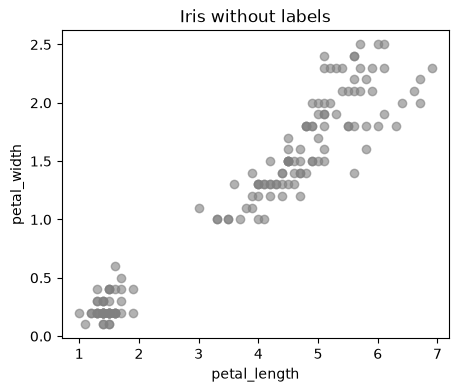

In [3]:
plt.figure(figsize=(5, 4))
plt.scatter(irisDF['petal_length'], irisDF['petal_width'], color='gray', alpha=0.6)
plt.xlabel('petal_length')
plt.ylabel('petal_width')
plt.title('Iris without labels')
plt.show()

**분류와 군집화의 코드 차이** (슬라이드 03의 표)

| | 분류 (지도 학습) | 군집화 (비지도 학습) |
|---|---|---|
| 학습 코드 | `model.fit(X, y)` | `model.fit(X)` |
| 결과 | 정해진 레이블 예측 | 숨은 그룹 번호(0, 1, 2, ...) 발견 |

아래 코드에서 `fit` 에 무엇을 넣는지 확인해 봄.

In [4]:
cols = ['petal_length', 'petal_width']
X_iris = irisDF[cols].values   # .values : DataFrame을 numpy 배열로 바꿈

km = KMeans(n_clusters=3, n_init=10, random_state=0)
km.fit(X_iris)          #빈칸 채우기 (군집화는 정답 y 없이 X만 넣음)
print('앞 10개 데이터의 군집 번호:', km.labels_[:10])

앞 10개 데이터의 군집 번호: [1 1 1 1 1 1 1 1 1 1]


> **생각해 보기 1-1.** 군집 번호 0, 1, 2는 품종 이름(setosa 등)과 같은 뜻일까요? 군집 번호에는 어떤 의미가 있는지 적어 보세요.
>
> 답: 군집 번호 0, 1, 2는 품종 이름이 아니라, 비슷한 측정값을 가진 점들을 묶은 그룹의 임의 식별자이다. 같은 번호이면 같은 군집이라는 뜻이며 번호의 크기나 순서에는 의미가 없다. 초기 중심이나 실행 조건이 바뀌면 같은 그룹에도 다른 번호가 붙을 수 있다. 정답 품종은 학습에 넣지 않았으므로 군집과 품종이 반드시 일대일로 대응하지는 않는다.

---
## 2. 거리 측정 (슬라이드 06)

군집화는 **거리가 가까우면 비슷하다**고 봄. 슬라이드의 수식을 함수로 직접 만들어 봄.

### 2-1. 유클리드 거리: `for` 문으로 만들기

$$d(x, y) = \sqrt{\sum_i (x_i - y_i)^2}$$

`Σ`(시그마)는 **모두 더하라**는 뜻이고, 코드에서는 `for` 문으로 하나씩 더하면 됨.

In [5]:
def euclidean(x, y):
    total = 0
    for i in range(len(x)):              # i = 0, 1, 2, ... 좌표 개수만큼 반복
        total = total + (x[i] - y[i]) ** 2   #빈칸 채우기 (제곱 연산자)
    return np.sqrt(total)

A = [1, 1]   # 슬라이드 06 그림의 x
B = [7, 7]   # 슬라이드 06 그림의 y
print('유클리드 거리:', euclidean(A, B))

유클리드 거리: 8.48528137423857


### 2-2. 맨해튼 거리와 민코프스키 거리

$$d_{맨해튼} = \sum_i |x_i - y_i| \qquad d_{민코프스키} = \left(\sum_i |x_i - y_i|^p\right)^{1/p}$$

numpy 배열을 쓰면 `for` 문 없이 **좌표끼리 한 번에** 계산할 수 있음.

In [6]:
def manhattan(x, y):
    x, y = np.array(x), np.array(y)
    return np.abs(x - y).sum()          #빈칸 채우기 (절댓값 함수)

def minkowski(x, y, p):
    x, y = np.array(x), np.array(y)
    return (np.abs(x - y) ** p).sum() ** (1 / p)   #빈칸 채우기 (1/p 제곱)

print('맨해튼 거리     :', manhattan(A, B))
print('민코프스키 (p=1):', minkowski(A, B, 1), '-> 맨해튼과 같음')
print('민코프스키 (p=2):', minkowski(A, B, 2), '-> 유클리드와 같음')

맨해튼 거리     : 12
민코프스키 (p=1): 12.0 -> 맨해튼과 같음
민코프스키 (p=2): 8.48528137423857 -> 유클리드와 같음


직접 만든 함수가 맞는지 라이브러리(`sklearn`)와 비교해 봄. 붓꽃 0번과 100번 꽃 사이의 거리임.

In [7]:
a = irisDF.iloc[0].values     # 0번 꽃 (4개 측정값)
b = irisDF.iloc[100].values   # 100번 꽃

print('유클리드 - 직접:', round(euclidean(a, b), 3),
      '/ sklearn:', round(pairwise_distances([a], [b], metric='euclidean')[0, 0], 3))
print('맨해튼   - 직접:', round(manhattan(a, b), 3),
      '/ sklearn:', round(pairwise_distances([a], [b], metric='manhattan')[0, 0], 3))   #빈칸 채우기

유클리드 - 직접: 5.285 / sklearn: 5.285
맨해튼   - 직접: 8.3 / sklearn: 8.3


### 2-3. 코사인 유사도와 자카드 계수 (유사도)

$$\cos\theta = \frac{x \cdot y}{\lVert x \rVert \, \lVert y \rVert} \qquad J(A, B) = \frac{|A \cap B|}{|A \cup B|}$$

- 코사인 유사도는 **방향**이 얼마나 같은지 봄. (-1 ~ 1, 같은 방향이면 1)
- 자카드 계수는 두 **집합**이 얼마나 겹치는지 봄. 파이썬의 `set` 으로 바로 계산할 수 있음.

In [8]:
def cosine_similarity(x, y):
    x, y = np.array(x), np.array(y)
    return np.dot(x, y) / (np.linalg.norm(x) * np.linalg.norm(y))   # np.dot: 내적, norm: 벡터의 길이

print('같은 방향 [1,2] vs [2,4]  :', round(cosine_similarity([1, 2], [2, 4]), 3))
print('수직      [1,0] vs [0,1]  :', round(cosine_similarity([1, 0], [0, 1]), 3))
print('반대 방향 [1,2] vs [-1,-2]:', round(cosine_similarity([1, 2], [-1, -2]), 3))

같은 방향 [1,2] vs [2,4]  : 1.0
수직      [1,0] vs [0,1]  : 0.0
반대 방향 [1,2] vs [-1,-2]: -1.0


In [9]:
def jaccard(set_a, set_b):
    inter = set_a & set_b      # 교집합
    union = set_a | set_b    #빈칸 채우기 (합집합 연산자)
    return len(inter) / len(union)

basket1 = {'사과', '딸기'}
basket2 = {'사과', '딸기', '바나나'}
print('교집합:', basket1 & basket2, '/ 합집합:', basket1 | basket2)
print('자카드 계수:', round(jaccard(basket1, basket2), 3), '(슬라이드 06의 2/3)')

교집합: {'딸기', '사과'} / 합집합: {'딸기', '사과', '바나나'}
자카드 계수: 0.667 (슬라이드 06의 2/3)


> **파이썬 기초 포인트**
> - `def 함수이름(입력):` 으로 함수를 만들고, `return` 으로 결과를 돌려줌.
> - `for i in range(len(x)):` 는 `x` 의 길이만큼 `i = 0, 1, 2, ...` 를 바꿔 가며 반복함.
> - numpy 배열끼리 `x - y` 를 하면 같은 위치끼리 한 번에 계산됨. (`for` 문을 대신함)
>
> **생각해 보기 2-1.** 장바구니 데이터처럼 '샀다/안 샀다'만 있는 데이터에는 유클리드 거리보다 자카드 계수가 더 어울리는 이유는 무엇일까요?
>
> 답: 장바구니에서는 두 사람이 함께 산 상품이 얼마나 겹치는지가 중요하다. 자카드 계수는 ‘공통으로 산 상품 수 / 둘 중 한 명이라도 산 상품 수’이므로, 둘 다 사지 않은 수많은 상품은 비교에서 제외하고 구매한 상품의 겹침을 비율로 나타낸다. 반면 이진 벡터의 유클리드 거리는 서로 구매 여부가 다른 상품 수의 제곱근이어서, 구매 상품 수가 다른 장바구니끼리 상대적인 겹침을 비교하기 어렵다. 따라서 구매 여부를 비대칭 이진 데이터로 볼 때 자카드가 잘 어울린다. 거리 기반 알고리즘에 넣으려면 자카드 거리인 `1 - 자카드 계수`를 사용한다.

---
## 3. 데이터 조정 (슬라이드 07)

### 3-1. 왜 조정해야 하나: 치우친 데이터
슬라이드 07 왼쪽 위 그림을 직접 만들어 봄. 방문 횟수(frequency)와 구매 금액(monetary)처럼 **한쪽으로 길게 치우친** 데이터임.

In [10]:
rng = np.random.default_rng(3)    # 난수 생성기 (3번 씨앗으로 고정하면 매번 같은 결과)
n = 300
frequency = rng.lognormal(1.0, 0.9, n)                  # 오른쪽으로 꼬리가 긴 분포
monetary = frequency * rng.lognormal(2.0, 0.6, n)
shop = pd.DataFrame({'frequency': frequency, 'monetary': monetary})

print(shop.describe().round(1))

       frequency  monetary
count      300.0     300.0
mean         4.3      39.6
std          5.0      58.8
min          0.2       0.7
25%          1.6      11.2
50%          2.8      23.6
75%          5.2      47.6
max         54.1     700.3


In [11]:
# 원본 그대로 스케일링만 하고 K-means (K=4)
X_raw = StandardScaler().fit_transform(shop)
label_raw = KMeans(n_clusters=4, n_init=10, random_state=0).fit_predict(X_raw)

# 로그 변환 후 스케일링하고 K-means
shop_log = np.log1p(shop)          #빈칸 채우기 (log(1 + x) 를 계산하는 numpy 함수)
X_log = StandardScaler().fit_transform(shop_log)
label_log = KMeans(n_clusters=4, n_init=10, random_state=0).fit_predict(X_log)

print('원본 그대로  군집 크기:', pd.Series(label_raw).value_counts().tolist())
print('로그 변환 후 군집 크기:', pd.Series(label_log).value_counts().tolist())

원본 그대로  군집 크기: [222, 64, 13, 1]
로그 변환 후 군집 크기: [113, 92, 59, 36]


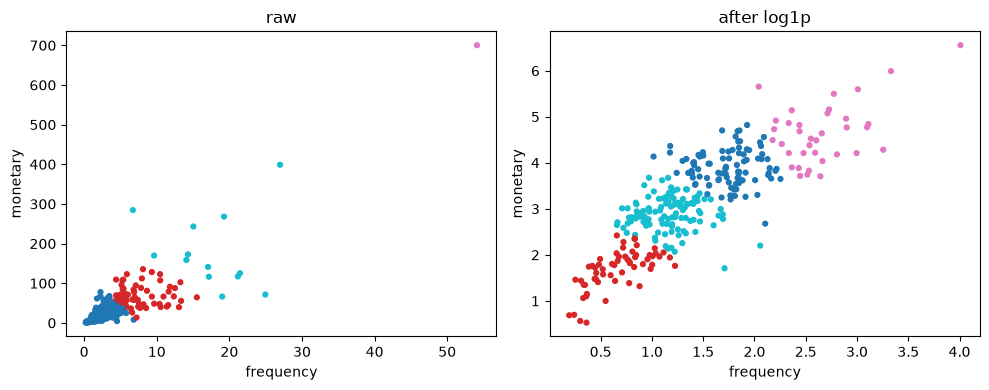

In [12]:
fig, axs = plt.subplots(1, 2, figsize=(10, 4))
axs[0].scatter(shop['frequency'], shop['monetary'], c=label_raw, cmap='tab10', s=12)
axs[0].set_title('raw')
axs[1].scatter(shop_log['frequency'], shop_log['monetary'], c=label_log, cmap='tab10', s=12)
axs[1].set_title('after log1p')
for ax in axs:
    ax.set_xlabel('frequency')
    ax.set_ylabel('monetary')
plt.tight_layout()
plt.show()

### 3-2. 스케일링: 수식을 직접 계산하기

$$z = \frac{x - \mu}{\sigma} \qquad (\mu: 평균,\ \sigma: 표준편차)$$

`StandardScaler` 가 하는 일을 직접 계산하고, 결과가 같은지 확인함.

In [13]:
mu = shop.mean()          # 열마다 평균
sigma = shop.std(ddof=0)  # 열마다 표준편차 (StandardScaler와 같은 방식)

z_manual = (shop - mu) / sigma       #빈칸 채우기 (평균을 빼고 표준편차로 나눔)
z_sklearn = StandardScaler().fit_transform(shop)

print('직접 계산 평균:', z_manual.mean().round(3).tolist(), '/ 표준편차:', z_manual.std(ddof=0).round(3).tolist())
print('sklearn과 같은가?', np.allclose(z_manual.values, z_sklearn))

직접 계산 평균: [-0.0, -0.0] / 표준편차: [1.0, 1.0]
sklearn과 같은가? True


### 3-3. 실제 데이터: 와인
와인 데이터는 `proline`(수백~천 단위)처럼 단위가 큰 변수가 섞여 있음.
정답 품종과 군집 결과가 얼마나 맞는지 **ARI**(1에 가까울수록 정답과 일치)로 비교함.

In [14]:
wine = load_wine()
wineDF = pd.DataFrame(wine.data, columns=wine.feature_names)
print(wineDF.std().sort_values(ascending=False).head(3).round(1))   # 표준편차가 큰 변수 3개

km = KMeans(n_clusters=3, n_init=10, random_state=0)
label_before = km.fit_predict(wineDF)
label_after = km.fit_predict(StandardScaler().fit_transform(wineDF))

print('\nARI 스케일링 전:', round(adjusted_rand_score(wine.target, label_before), 3))
print('ARI 스케일링 후:', round(adjusted_rand_score(wine.target, label_after), 3))

proline              314.9
magnesium             14.3
alcalinity_of_ash      3.3
dtype: float64

ARI 스케일링 전: 0.371
ARI 스케일링 후: 0.897


> **파이썬 기초 포인트**
> - `shop.mean()` 처럼 DataFrame에 함수를 쓰면 **열마다** 계산됨.
> - `shop - mu` 는 각 열에서 그 열의 평균을 빼 줌.
> - `pd.Series(...).value_counts()` 는 값마다 몇 개인지 세어 줌.
>
> **생각해 보기 3-1.** 원본 그대로 군집화했을 때 크기가 1이나 13인 작은 군집이 생긴 이유를 슬라이드 07 내용으로 설명해 보세요.
>
> 답: frequency와 monetary가 오른쪽으로 긴 꼬리를 가지므로, 대부분은 작은 값에 몰리고 일부 고객만 매우 큰 값을 가진다. 표준화는 평균과 단위만 바꾸므로 이러한 치우침이나 극단값의 영향까지 제거하지는 못한다. K-means는 중심까지 거리의 제곱합을 줄이므로 큰 값을 가진 소수의 점에 중심을 따로 배정할 수 있다. 실제로 원본을 표준화한 결과는 군집 크기가 222, 64, 13, 1로 나뉜다. `log1p`는 큰 값을 더 강하게 압축해 극단값의 영향을 줄이며, 로그 변환 후에는 113, 92, 59, 36으로 나뉜다. 다만 군집 크기가 균등하다는 사실만으로 좋은 군집이라고 판단할 수는 없다.

---
## 4. K-means (슬라이드 08~09)

### 4-1. K-means 직접 만들기
슬라이드 08의 네 단계를 그대로 코드로 옮김.
1. 중심 K개를 임의로 고름
2. 각 점을 가장 가까운 중심에 **할당**
3. 군집마다 평균을 내서 중심을 **이동**
4. 중심이 변하지 않으면 종료 (아니면 2로 돌아감)

반복 횟수: 2


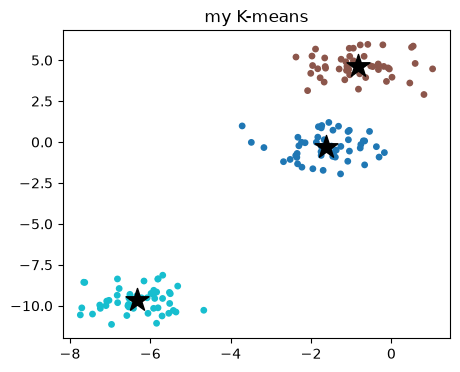

In [15]:
X, y_true = make_blobs(n_samples=150, centers=3, cluster_std=0.8, random_state=11)

def my_kmeans(X, k, seed=0):
    rng = np.random.default_rng(seed)
    centers = X[rng.choice(len(X), size=k, replace=False)]    # 1. 데이터 중 k개를 임의로 골라 중심으로
    step = 0
    while True:
        # 2. 할당: 각 점에서 각 중심까지의 거리를 구하고, 가장 가까운 중심 번호를 고름
        dist = pairwise_distances(X, centers)                   # (점 개수, k) 크기의 거리 표
        labels = dist.argmin(axis=1)                         #빈칸 채우기 (가장 작은 값의 위치)

        # 3. 이동: 군집마다 속한 점들의 평균을 새 중심으로
        new_centers = np.array([X[labels == j].mean(axis=0) for j in range(k)])   #빈칸 채우기

        step = step + 1
        # 4. 종료: 중심이 거의 움직이지 않으면 멈춤
        if np.allclose(new_centers, centers):
            break
        centers = new_centers
    return labels, centers, step

labels, centers, step = my_kmeans(X, k=3)
print('반복 횟수:', step)

plt.figure(figsize=(5, 4))
plt.scatter(X[:, 0], X[:, 1], c=labels, cmap='tab10', s=15)
plt.scatter(centers[:, 0], centers[:, 1], marker='*', s=300, c='black')
plt.title('my K-means')
plt.show()

> **파이썬 기초 포인트**
> - `while True:` 는 계속 반복하다가 `break` 를 만나면 멈춤.
> - `X[labels == j]` 는 **불리언 인덱싱**임. `labels` 가 `j` 인 점들만 골라냄.
> - `[식 for j in range(k)]` 는 **리스트 컴프리헨션**으로, 반복 결과를 리스트로 한 번에 만듦.

### 4-2. 이너셔(SSE) 직접 계산하기

$$J = \sum_{k=1}^{K} \sum_{x \in C_k} \lVert x - \mu_k \rVert^2$$

각 점과 **자기 군집 중심** 사이 거리의 제곱을 모두 더한 값임. sklearn의 `inertia_` 와 비교함.

In [16]:
sse = 0
for j in range(3):
    points = X[labels == j]                       # j번 군집의 점들
    sse = sse + ((points - centers[j]) ** 2).sum()   #빈칸 채우기 (모두 더하기)

km = KMeans(n_clusters=3, n_init=10, random_state=0).fit(X)
print('직접 계산한 이너셔:', round(sse, 2))
print('sklearn inertia_  :', round(km.inertia_, 2))

직접 계산한 이너셔: 170.72
sklearn inertia_  : 170.72


### 4-3. 한계: 초기 중심과 모양 (슬라이드 09)
`seed` 를 바꾸면 처음 고르는 중심이 달라짐. 중심이 8개인 데이터에서 결과가 얼마나 흔들리는지 확인함.

In [17]:
X8, _ = make_blobs(n_samples=400, centers=8, cluster_std=0.6, random_state=7)

for seed in range(5):
    km = KMeans(n_clusters=8, init='random', n_init=1, random_state=seed).fit(X8)
    print(f'seed {seed}: 이너셔 {km.inertia_:.1f}')

km_best = KMeans(n_clusters=8, init='random', n_init=10, random_state=0).fit(X8)   #빈칸 채우기 (10번 시도해 가장 좋은 결과)
print(f'n_init=10: 이너셔 {km_best.inertia_:.1f}')

seed 0: 이너셔 385.0


seed 1: 이너셔 3063.3
seed 2: 이너셔 954.9
seed 3: 이너셔 825.1
seed 4: 이너셔 824.4
n_init=10: 이너셔 259.9


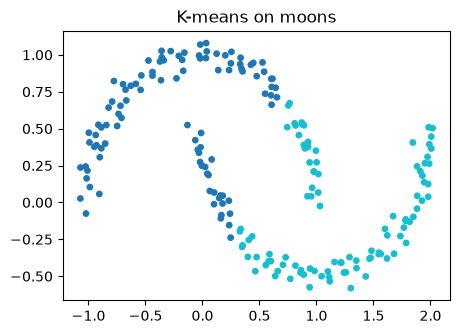

ARI: 0.256


In [18]:
X_moon, y_moon = make_moons(n_samples=200, noise=0.05, random_state=0)
label_moon = KMeans(n_clusters=2, n_init=10, random_state=0).fit_predict(X_moon)

plt.figure(figsize=(5, 3.5))
plt.scatter(X_moon[:, 0], X_moon[:, 1], c=label_moon, cmap='tab10', s=15)
plt.title('K-means on moons')
plt.show()
print('ARI:', round(adjusted_rand_score(y_moon, label_moon), 3))

> **생각해 보기 4-1.** 초승달 데이터에서 K-means가 직선으로 잘라 버리는 이유를 4-1에서 만든 함수의 **할당 단계** 코드와 연결해 설명해 보세요.
>
> 답: 할당 단계의 `dist = pairwise_distances(X, centers)`는 각 점과 중심 사이의 유클리드 거리를 구하고, `labels = dist.argmin(axis=1)`는 가장 가까운 중심 하나를 선택한다. 중심이 두 개일 때 두 중심까지의 거리가 같은 점들의 경계는 두 중심을 잇는 선분의 수직이등분선이다. 따라서 2차원 공간을 직선으로 나누며, 초승달을 따라 이어지는 이웃 관계나 곡선 모양은 고려하지 않는다. 그 결과 각각의 초승달을 하나의 군집으로 묶지 못하고 곡선 중간을 가로질러 나누며, 이 실험의 ARI는 약 0.256이다.

---
## 5. 계층 군집 (슬라이드 10~11)

### 5-1. 덴드로그램 그리고 두 높이에서 자르기
점 8개(A~H)로 덴드로그램을 그리고, 슬라이드 10처럼 **높이 h** 에서 잘라 군집 수가 어떻게 달라지는지 확인함.

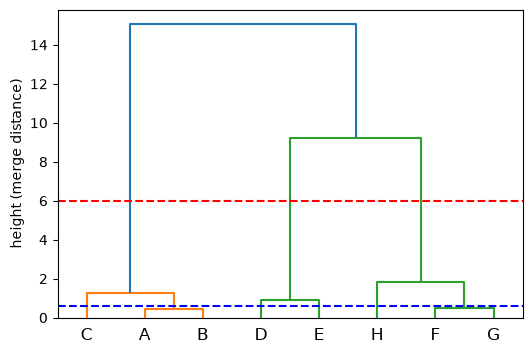

In [19]:
points = np.array([[0, 0], [0.4, 0.2], [1.2, 0.5],          # A, B, C
                   [5, 5], [5.8, 5.4],                       # D, E
                   [9, 0.5], [9.3, 0.9], [10.5, 1.5]])       # F, G, H
names = ['A', 'B', 'C', 'D', 'E', 'F', 'G', 'H']

Z = linkage(points, method='ward')    # 병합 과정 기록

plt.figure(figsize=(6, 4))
dendrogram(Z, labels=names)
plt.axhline(y=6, color='red', linestyle='--')
plt.axhline(y=0.6, color='blue', linestyle='--')
plt.ylabel('height (merge distance)')
plt.show()

In [20]:
for h in [6, 0.6]:
    groups = fcluster(Z, t=h, criterion='distance')   #빈칸 채우기 (높이 기준으로 자르기)
    n_clusters = len(set(groups))                        # set: 중복을 없애 군집 번호 종류만 남김
    print(f'높이 {h}에서 자르면 군집 {n_clusters}개:', dict(zip(names, groups.tolist())))

높이 6에서 자르면 군집 3개: {'A': 1, 'B': 1, 'C': 1, 'D': 2, 'E': 2, 'F': 3, 'G': 3, 'H': 3}
높이 0.6에서 자르면 군집 6개: {'A': 1, 'B': 1, 'C': 2, 'D': 3, 'E': 4, 'F': 5, 'G': 5, 'H': 6}


### 5-2. 연결 방법 비교 (슬라이드 11)
군집 사이 거리를 어떻게 재는지(single, complete, average, ward)에 따라 결과가 달라짐.
반복문으로 네 가지를 모두 돌려 **결과 표**를 만들어 봄.

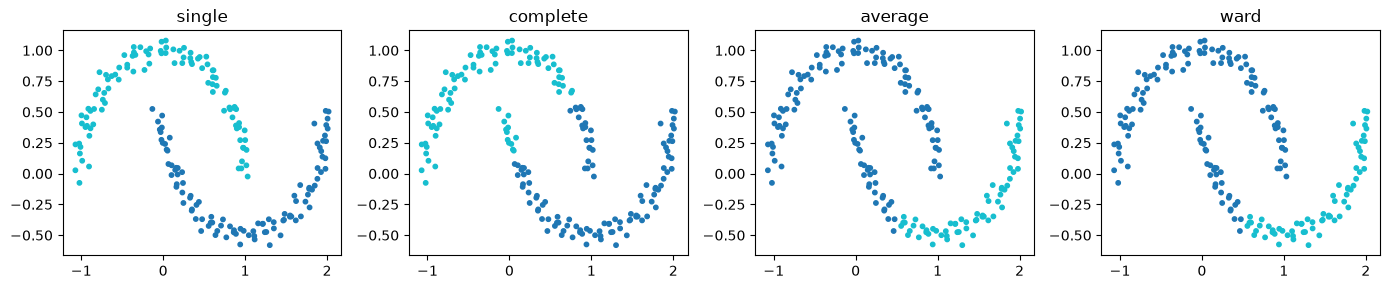

{'single': 1.0, 'complete': 0.433, 'average': 0.433, 'ward': 0.433}

In [21]:
results = {}                                  # 빈 딕셔너리: {연결 방법: ARI}
fig, axs = plt.subplots(1, 4, figsize=(14, 3))

for i, method in enumerate(['single', 'complete', 'average', 'ward']):
    model = AgglomerativeClustering(n_clusters=2, linkage=method)   #빈칸 채우기 (반복 변수)
    labels = model.fit_predict(X_moon)
    results[method] = round(adjusted_rand_score(y_moon, labels), 3)    # 딕셔너리에 저장
    axs[i].scatter(X_moon[:, 0], X_moon[:, 1], c=labels, cmap='tab10', s=10)
    axs[i].set_title(method)

plt.tight_layout()
plt.show()
results

> **파이썬 기초 포인트**
> - `enumerate(리스트)` 는 `(번호, 값)` 을 함께 꺼내 줌. 그래프 칸 번호 `i` 로 썼음.
> - `results[method] = 값` 처럼 딕셔너리에 **키: 값** 을 추가할 수 있음.
>
> **생각해 보기 5-1.** 초승달 데이터에서 single 연결이 가장 잘 맞는 이유를 슬라이드 11의 설명(길게 이어진 군집)으로 적어 보세요.
>
> 답: single 연결은 두 군집에 속한 점들 사이 거리 중 최솟값을 군집 사이 거리로 사용한다. 초승달의 양 끝은 멀어도 곡선을 따라 이웃한 점들은 가까우므로, 가까운 점들을 차례로 연결해 길게 이어진 하나의 군집을 만들 수 있다. 현재 데이터에서는 두 초승달 사이보다 각 초승달 안의 이웃 간격이 작아 모양을 잘 복원하며, single의 ARI는 1.000이고 다른 세 방법은 약 0.433이다. 다만 잡음이 두 군집 사이에 다리처럼 놓이면 서로 다른 군집도 이어지는 chaining 현상이 생길 수 있다.

---
## 6. DBSCAN (슬라이드 12)

### 6-1. ε-이웃과 core 조건 직접 확인하기

$$N_\varepsilon(p) = \{\, q : d(p, q) \le \varepsilon \,\} \qquad |N_\varepsilon(p)| \ge \text{min\_samples} \ \Rightarrow\ \text{core}$$

점마다 반경 ε 안에 있는 이웃 수를 세고, `min_samples` 이상이면 core로 판단함.

In [22]:
# 슬라이드 12 아래 그림: 가상의 주택 좌표
rng = np.random.default_rng(8)
town_a = rng.normal([2.5, 7], [0.5, 0.45], (26, 2))
t = rng.uniform(0, 1, 24)
town_b = np.c_[5 + 4 * t, 2 + 1.2 * t] + rng.normal(0, 0.18, (24, 2))   # 길을 따라 길게 이어진 구역
town_c = rng.normal([8, 7.2], [0.45, 0.5], (20, 2))
lonely = rng.uniform([0.5, 0.5], [10, 9.5], (9, 2))                     # 여기저기 흩어진 외딴 집
houses = np.vstack([town_a, town_b, town_c, lonely])
print('집 개수:', len(houses))

집 개수: 79


In [23]:
eps = 0.8
min_samples = 5

dist = pairwise_distances(houses)        # 모든 집 사이 거리 표
is_core = []                             # 빈 리스트
for i in range(len(houses)):
    n_neighbors = (dist[i] <= eps).sum()   #빈칸 채우기 (반경 안에 있는 이웃 수, 자기 자신 포함)
    if n_neighbors >= min_samples:
        is_core.append(True)
    else:
        is_core.append(False)

print('직접 센 core 개수:', sum(is_core))

직접 센 core 개수: 68


sklearn core 개수: 68
군집 수: 3
noise(외딴 집) 수: 6


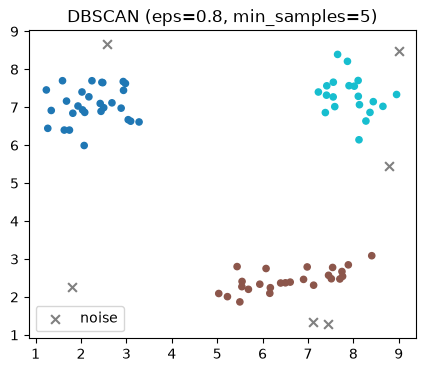

In [24]:
db = DBSCAN(eps=eps, min_samples=min_samples).fit(houses)
labels = db.labels_                       # -1 은 noise

print('sklearn core 개수:', len(db.core_sample_indices_))
print('군집 수:', len(set(labels)) - (1 if -1 in labels else 0))
print('noise(외딴 집) 수:', (labels == -1).sum())   #빈칸 채우기 (noise를 뜻하는 번호)

plt.figure(figsize=(5, 4))
plt.scatter(houses[labels != -1, 0], houses[labels != -1, 1], c=labels[labels != -1], cmap='tab10', s=20)
plt.scatter(houses[labels == -1, 0], houses[labels == -1, 1], marker='x', c='gray', s=40, label='noise')
plt.legend()
plt.title(f'DBSCAN (eps={eps}, min_samples={min_samples})')
plt.show()

### 6-2. eps를 바꿔 보기
반복문으로 eps를 바꿔 가며 군집 수와 noise 수를 표로 정리함.

In [25]:
rows = []
for e in [0.3, 0.5, 0.8, 1.2, 2.0]:
    lab = DBSCAN(eps=e, min_samples=5).fit_predict(houses)
    rows.append({'eps': e,
                 'n_clusters': len(set(lab)) - (1 if -1 in lab else 0),
                 'n_noise': int((lab == -1).sum())})
pd.DataFrame(rows)

,eps,n_clusters,n_noise
0,0.3,2,67
1,0.5,4,17
2,0.8,3,6
3,1.2,3,1
4,2.0,3,1


> **파이썬 기초 포인트**
> - `if 조건: ... else: ...` 로 조건에 따라 다른 일을 함.
> - `리스트.append(값)` 은 리스트 끝에 값을 하나 추가함.
> - `sum(is_core)` 처럼 True/False 리스트를 더하면 True의 개수가 나옴.
>
> **생각해 보기 6-1.** eps가 너무 작을 때와 너무 클 때 각각 어떤 결과가 나왔나요? 이유도 적어 보세요.
>
> 답: `min_samples=5`를 고정했을 때 실제 결과는 다음과 같다.
>
> | eps | 군집 수 | noise 수 |
> |---:|---:|---:|
> | 0.3 | 2 | 67 |
> | 0.5 | 4 | 17 |
> | 0.8 | 3 | 6 |
> | 1.2 | 3 | 1 |
> | 2.0 | 3 | 1 |
>
> eps가 너무 작으면 반경 안의 이웃 수가 부족해 core가 되지 못하는 점이 많아지고, 많은 점이 noise가 되거나 원래 이어져야 할 군집이 쪼개진다. 특히 0.3에서는 대부분이 noise라 군집 수 자체도 2개로 작다. eps를 늘리면 이웃과 core가 늘어 noise가 줄고 떨어져 있던 부분들이 연결될 수 있다. 이 실험에서는 1.2와 2.0에서도 군집 3개가 유지되므로 ‘2.0에서 모두 합쳐졌다’고 해석하면 안 된다. 이보다 지나치게 큰 eps를 쓰면 서로 다른 구역까지 밀도 연결되어 군집이 합쳐지고, 충분히 커지면 거의 모든 점이 한 군집이 될 수 있다. 군집 수는 eps에 따라 단순히 증가하거나 감소하는 것은 아니다.

---
## 7. 실루엣 계수 (슬라이드 13)

$$a(i) = \text{mean}_{j \in C_i,\, j \ne i}\ d(i, j) \qquad b(i) = \min_{C \ne C_i}\ \text{mean}_{j \in C}\ d(i, j) \qquad s(i) = \frac{b(i) - a(i)}{\max(a(i),\, b(i))}$$

- a(i): 같은 군집 안의 다른 점들까지 평균 거리 (**응집도**, 작을수록 좋음)
- b(i): 가장 가까운 다른 군집까지 평균 거리 (**분리도**, 클수록 좋음)

### 7-1. 한 점의 실루엣 계수 직접 계산하기

In [26]:
X_s = StandardScaler().fit_transform(irisDF)
labels = KMeans(n_clusters=3, n_init=10, random_state=0).fit_predict(X_s)
D = pairwise_distances(X_s)

def silhouette_one(i, labels, D):
    same = (labels == labels[i])
    same[i] = False                                   # 자기 자신은 빼기
    a = D[i, same].mean()                             # a(i)

    b_list = []
    for c in set(labels):                             # 다른 군집마다 평균 거리 구하기
        if c != labels[i]:
            b_list.append(D[i, labels == c].mean())
    b = min(b_list)                                 #빈칸 채우기 (가장 가까운 군집)

    return (b - a) / max(a, b)

i = 0
print(f'{i}번 점의 실루엣 (직접)  :', round(silhouette_one(i, labels, D), 4))
print(f'{i}번 점의 실루엣 (sklearn):', round(silhouette_samples(X_s, labels)[i], 4))

0번 점의 실루엣 (직접)  : 0.7342


0번 점의 실루엣 (sklearn): 0.7342


### 7-2. 전체 점수 = 모든 점의 평균

In [27]:
my_scores = [silhouette_one(i, labels, D) for i in range(len(X_s))]
print('직접 계산 평균  :', round(np.mean(my_scores), 4))      #빈칸 채우기
print('silhouette_score:', round(silhouette_score(X_s, labels), 4))

직접 계산 평균  : 0.4599
silhouette_score: 0.4599


### 7-3. 실루엣 다이어그램 (슬라이드 13 왼쪽 아래)

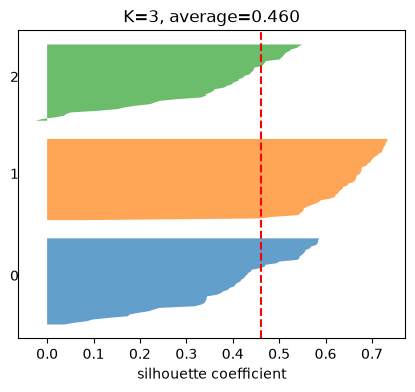

In [28]:
def visualize_silhouette(X, labels):
    values = silhouette_samples(X, labels)
    avg = values.mean()
    y_low = 10
    plt.figure(figsize=(5, 4))
    for c in sorted(set(labels)):
        v = np.sort(values[labels == c])
        plt.fill_betweenx(np.arange(y_low, y_low + len(v)), 0, v, alpha=0.7)
        plt.text(-0.08, y_low + len(v) / 2, str(c))
        y_low = y_low + len(v) + 10
    plt.axvline(avg, color='red', linestyle='--')
    plt.xlabel('silhouette coefficient')
    plt.yticks([])
    plt.title(f'K={len(set(labels))}, average={avg:.3f}')
    plt.show()

visualize_silhouette(X_s, labels)

> **생각해 보기 7-1.** 실루엣 계수가 음수인 점은 어떤 상태인가요? 슬라이드 13의 해석 막대를 보고 적어 보세요.
>
> 답: 실루엣 계수가 음수이면 `a(i) > b(i)`이다. 즉, 자기 군집 안의 다른 점들까지의 평균 거리보다 가장 가까운 다른 군집의 점들까지의 평균 거리가 더 작다. 현재 군집보다 다른 군집에 더 잘 어울릴 가능성이 있어 잘못 배정되었거나 군집이 겹치는 영역에 있는 점으로 해석할 수 있다. -1에 가까울수록 이러한 경향이 강하고, 0 부근은 군집 경계가 모호한 상태이다. 다만 음수라는 사실만으로 실제 정답을 틀렸다고 단정할 수는 없다.

---
## 8. 최적의 K 찾기 (슬라이드 14)

K를 2부터 9까지 바꿔 가며 **이너셔(WCSS)** 와 **실루엣 점수**를 리스트에 모아 그래프로 그림.

$$WCSS(K) = \sum_{k=1}^{K} \sum_{x \in C_k} \lVert x - \mu_k \rVert^2$$

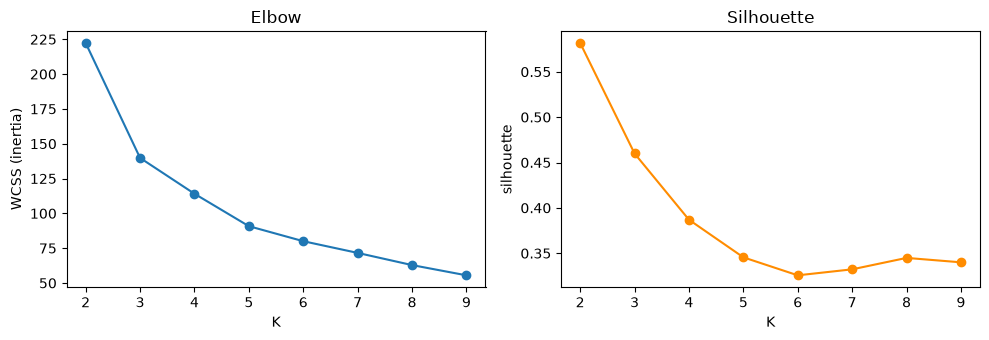

실루엣 점수가 가장 높은 K: 2
경험 법칙 sqrt(n/2): 8.7


In [29]:
k_list = list(range(2, 10))
wcss = []
sil = []

for k in k_list:
    km = KMeans(n_clusters=k, n_init=10, random_state=0).fit(X_s)
    wcss.append(km.inertia_)                       #빈칸 채우기 (리스트에 추가)
    sil.append(silhouette_score(X_s, km.labels_))

fig, axs = plt.subplots(1, 2, figsize=(10, 3.5))
axs[0].plot(k_list, wcss, marker='o')
axs[0].set_xlabel('K'); axs[0].set_ylabel('WCSS (inertia)'); axs[0].set_title('Elbow')
axs[1].plot(k_list, sil, marker='o', color='darkorange')
axs[1].set_xlabel('K'); axs[1].set_ylabel('silhouette'); axs[1].set_title('Silhouette')
plt.tight_layout()
plt.show()

best_k = k_list[int(np.argmax(sil))]
print('실루엣 점수가 가장 높은 K:', best_k)
print('경험 법칙 sqrt(n/2):', round(np.sqrt(len(X_s) / 2), 1))

> **생각해 보기 8-1.** 붓꽃은 실제 품종이 3개인데, 실루엣 점수는 K=2에서 더 높게 나올 수 있음. 왜 그런지 1번 파트의 산점도를 떠올리며 적어 보세요.
>
> 답: 꽃잎 길이와 너비의 산점도에서 setosa는 다른 두 품종과 뚜렷이 떨어져 있지만 versicolor와 virginica는 일부 겹치고 상대적으로 가깝다. 따라서 K=2로 setosa와 나머지를 나누면 군집 사이 거리가 크고 각 군집 내부도 비교적 응집되어 평균 실루엣이 높을 수 있다. K=3은 서로 가까운 두 품종 영역을 다시 나누므로 경계 부근 점들의 분리도가 낮아진다. 실제 전체 4개 특성을 표준화한 실험에서도 K=2가 가장 높은 점수를 보인다. 실루엣은 입력 특성 공간에서의 응집도와 분리도를 평가하는 지표이며 실제 품종 개수나 분류 정답과의 일치를 직접 평가하지 않는다.

---
## 9. 정리: 실습 흐름 한 번에 (슬라이드 15~16)

슬라이드 16의 네 단계를 **함수 하나**로 묶어 와인 데이터에 적용함.

STEP 1 전처리 → STEP 2 K 정하기 → STEP 3 모델 학습 → STEP 4 결과 해석

In [30]:
def run_clustering(df, k_candidates=range(2, 7)):
    # STEP 1. 전처리: 스케일링
    X = StandardScaler().fit_transform(df)

    # STEP 2. K 정하기: 실루엣 점수가 가장 높은 K
    scores = {}
    for k in k_candidates:
        lab = KMeans(n_clusters=k, n_init=10, random_state=0).fit_predict(X)
        scores[k] = silhouette_score(X, lab)
    best_k = max(scores, key=scores.get)
    print('K별 실루엣:', {k: round(v, 3) for k, v in scores.items()})
    print('선택한 K:', best_k)

    # STEP 3. 모델 학습
    labels = KMeans(n_clusters=best_k, n_init=10, random_state=0).fit_predict(X)   #빈칸 채우기

    # STEP 4. 결과 해석: 군집별 평균 비교
    result = df.copy()
    result['cluster'] = labels
    return result.groupby('cluster').mean()

use_cols = ['alcohol', 'malic_acid', 'color_intensity', 'proline']
summary = run_clustering(wineDF[use_cols])
summary.round(2)

K별 실루엣: {2: 0.339, 3: 0.399, 4: 0.393, 5: 0.325, 6: 0.3}
선택한 K: 3


,alcohol,malic_acid,color_intensity,proline
cluster,,,,
0,12.29,1.87,3.27,525.67
1,13.26,3.59,7.11,655.78
2,13.77,1.79,5.64,1155.33


> **생각해 보기 9-1.** 위 표의 군집별 평균을 보고, 각 군집에 어울리는 이름을 붙여 보세요. (예: 도수 높고 진한 와인)
>
> **생각해 보기 9-2.** 같은 와인 데이터에 DBSCAN이나 계층 군집을 쓰려면 `run_clustering` 함수의 어느 줄을 바꾸면 될까요?
>
> **9-1 답:** 선택된 K는 3이며, 원래 단위로 계산한 군집별 평균을 바탕으로 다음과 같이 이름을 붙일 수 있다.
>
> | 군집 | alcohol | malic_acid | color_intensity | proline | 이름 |
> |---:|---:|---:|---:|---:|---|
> | 0 | 12.29 | 1.87 | 3.27 | 525.67 | 도수가 낮고 색이 옅은 와인 |
> | 1 | 13.26 | 3.59 | 7.11 | 655.78 | 말산이 많고 색이 가장 진한 와인 |
> | 2 | 13.77 | 1.79 | 5.64 | 1155.33 | 도수가 가장 높고 프롤린이 많은 와인 |
>
> 이름은 이 데이터 안에서의 상대적인 특징을 요약한 것이며, 군집 번호 자체에 순서나 품종 의미는 없다. 다른 실행 조건에서 번호가 바뀌면 평균값을 보고 이름을 다시 대응시켜야 한다.
>
> **9-2 답:** STEP 1의 `StandardScaler` 전처리와 STEP 4의 군집별 평균 계산은 유지하고, STEP 2의 매개변수 선택과 STEP 3의 모델 학습을 바꾸면 된다.
>
> **계층 군집:** STEP 2의 K별 반복문에서 `KMeans(...).fit_predict(X)`를 `AgglomerativeClustering(n_clusters=k, linkage='ward').fit_predict(X)`로 바꾼다. 실루엣으로 `best_k`를 선택하는 코드는 그대로 사용할 수 있다. STEP 3도 다음과 같이 바꾼다.
>
> ```python
> labels = AgglomerativeClustering(n_clusters=best_k, linkage='ward').fit_predict(X)
> ```
>
> **DBSCAN:** K를 지정하지 않으므로 STEP 2의 K 후보 반복문과 `best_k` 선택을 제거하고, 표준화한 공간에서 사용할 `eps`와 `min_samples`를 정하거나 후보별로 비교한다. STEP 3은 예를 들어 다음과 같이 바꾼다. 아래 값은 시작 예시이며 데이터에 맞게 조정해야 한다.
>
> ```python
> labels = DBSCAN(eps=0.8, min_samples=5).fit_predict(X)
> ```
>
> STEP 4에서는 `-1`이 noise라는 점도 반영한다. 군집별 평균에 noise를 포함하지 않으려면 다음처럼 바꾸고 noise 수는 따로 확인한다.
>
> ```python
> result = df.copy()
> result['cluster'] = labels
> print('noise 수:', int((labels == -1).sum()))
> return result.loc[result['cluster'] != -1].groupby('cluster').mean()
> ```
>
> DBSCAN 후보를 실루엣으로 비교한다면 noise를 제외한 데이터와 레이블로 계산하고, `2 <= 군집 수 <= noise 제외 표본 수 - 1`인 경우에만 계산해야 한다. noise를 제외하고 군집이 하나뿐이거나 전부 noise이면 실루엣을 계산할 수 없다. noise 비율도 함께 확인해야 한다.